# Slide 9: TGLF default width search against GS2 (white-background version of the poster panel)

Fusion_PhD-qp5.31 (STEP GK talk, 2 Nov 2026), adapted from `notebooks/TGLF_numerics/tglf_search_bias_vs_gs2.ipynb`
(branch `analysis/tglf-search-bias`, qp5.30). The poster panel ("TGLF default", points coloured by $k_y\rho_s$) used the GP-MODELS
dataset; this version uses the KBM population of every other slide: the GS2-KBM samples (user classifier) of the SPR-045 and M1
`kbm_8d` hypercubes (119 / 161).

- TGLF: `TGLF/Runs/kbm_tglf_find_width/<db>/fw_nbmin2_nb32_nx32_fp2p0_r0p3_1p65` (FIND_WIDTH T, NBASIS_MIN 2, search 0.3-1.65,
  FILTER 2, NBASIS_MAX 32; qp5.21). The filter stays on (user: "when you run with a width search ... still use a filter").
- GS2: `pyro_cube_avg` tail average; classifier from the final-time `pyro_cube`.
- Bias: $r = \log_{10}(\gamma_{\rm TGLF}/\gamma_{\rm GS2})$ over cases where TGLF finds an unstable mode; bootstrap 95% CI of the median.

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# slide-readable at the saved size, white background (user, 2026-11-01)
plt.rcParams.update({"font.size": 20, "axes.labelsize": 22, "axes.titlesize": 22, "xtick.labelsize": 20, "ytick.labelsize": 20,
                     "legend.fontsize": 19, "lines.linewidth": 2.5, "lines.marker": "", "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white", "savefig.dpi": 200})
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
import json
import re
from matplotlib.colors import LogNorm
from pyrokinetics import PyroHypercube
from general_analysis import mode_classification as mc

data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
databases = ["SPR-045", "M1"]
rng = np.random.default_rng(0)

In [2]:
gamma_gs2, gamma_tglf, ky_gs2 = [], [], []
for database in databases:
    gs2_dir = data_root / "GS2" / "Runs" / "LATIN_HYPERCUBE" / database / "kbm_8d"
    gs2_scan = mc.attach_legacy_funcs(PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube" / "pyroscan.json", load_base_pyro=True))
    gs2_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube" / "cube.nc")
    gs2_avg_scan = PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube_avg" / "pyroscan.json", load_base_pyro=True)
    gs2_avg_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube_avg" / "cube.nc")
    gs2_avg = gs2_avg_scan.gk_output.data
    names = gs2_avg.sample_name.values.astype(str)
    assert (gs2_scan.gk_output.data.sample_name.values.astype(str) == names).all()
    label = np.asarray(mc.classify(mc.indicators(gs2_scan, gs2_scan.gk_output.data)))
    growth_gs2 = gs2_avg.growth_rate.pint.dequantify().values.ravel()
    kbm = (label == "KBM") & np.isfinite(growth_gs2) & (growth_gs2 > 0)
    print(database, "GS2-KBM:", kbm.sum())

    leaf = data_root / "TGLF/Runs/kbm_tglf_find_width" / database / "fw_nbmin2_nb32_nx32_fp2p0_r0p3_1p65"
    tglf_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    tglf_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]   # settings GyroRun put on the source deck
    print(database, leaf.name, {k: flags[k] for k in ("FIND_WIDTH", "NBASIS_MIN", "NBASIS_MAX", "NXGRID", "FILTER") if k in flags})
    tglf = tglf_scan.gk_output.data.set_index(sample="sample_name").sel(sample=names[kbm])
    assert str(tglf.growth_rate.data.units) == re.sub(r"_pyroscan_base\d+", "", str(gs2_avg.growth_rate.data.units)), "normalisations differ"
    growth = tglf.growth_rate.pint.dequantify()
    assert int(tglf_scan.base_pyro.gk_input.data["ibranch"]) == -1 and (growth.fillna(-np.inf).argmax("mode") == 0).all()  # mode 0 = dominant
    gamma_tglf.append(growth.isel(mode=0).clip(min=0).values.ravel())
    gamma_gs2.append(growth_gs2[kbm])
    ky_sampled = gs2_avg["ky"].pint.dequantify().values.ravel()           # the cube's sampled ky (pyro units, k_y rho_s)
    assert ky_sampled.size == names.size
    ky_gs2.append(ky_sampled[kbm])
gamma_tglf, gamma_gs2, ky_gs2 = (np.concatenate(values) for values in (gamma_tglf, gamma_gs2, ky_gs2))

SPR-045 GS2-KBM: 119


SPR-045 fw_nbmin2_nb32_nx32_fp2p0_r0p3_1p65 {'FIND_WIDTH': True, 'NBASIS_MIN': 2, 'NBASIS_MAX': 32, 'NXGRID': 32, 'FILTER': 2.0}


M1 GS2-KBM: 161


M1 fw_nbmin2_nb32_nx32_fp2p0_r0p3_1p65 {'FIND_WIDTH': True, 'NBASIS_MIN': 2, 'NBASIS_MAX': 32, 'NXGRID': 32, 'FILTER': 2.0}


In [3]:
found = gamma_tglf > 0
log_ratio = np.log10(gamma_tglf[found] / gamma_gs2[found])
boot = [np.median(rng.choice(log_ratio, log_ratio.size)) for _ in range(10000)]
n_found, n_miss = int(found.sum()), int((~found).sum())
fraction_above = float((log_ratio > 0).mean())
median_ratio, ci_low, ci_high = 10 ** np.median(log_ratio), 10 ** np.percentile(boot, 2.5), 10 ** np.percentile(boot, 97.5)
print(f"n = {n_found} (+{n_miss} TGLF misses) | above y=x {100 * fraction_above:.1f}% | median ratio x{median_ratio:.2f} "
      f"(95% CI x{ci_low:.2f}-x{ci_high:.2f}) | median log10 ratio {np.median(log_ratio):+.3f}")

n = 275 (+5 TGLF misses) | above y=x 78.9% | median ratio x2.64 (95% CI x2.18-x3.28) | median log10 ratio +0.421


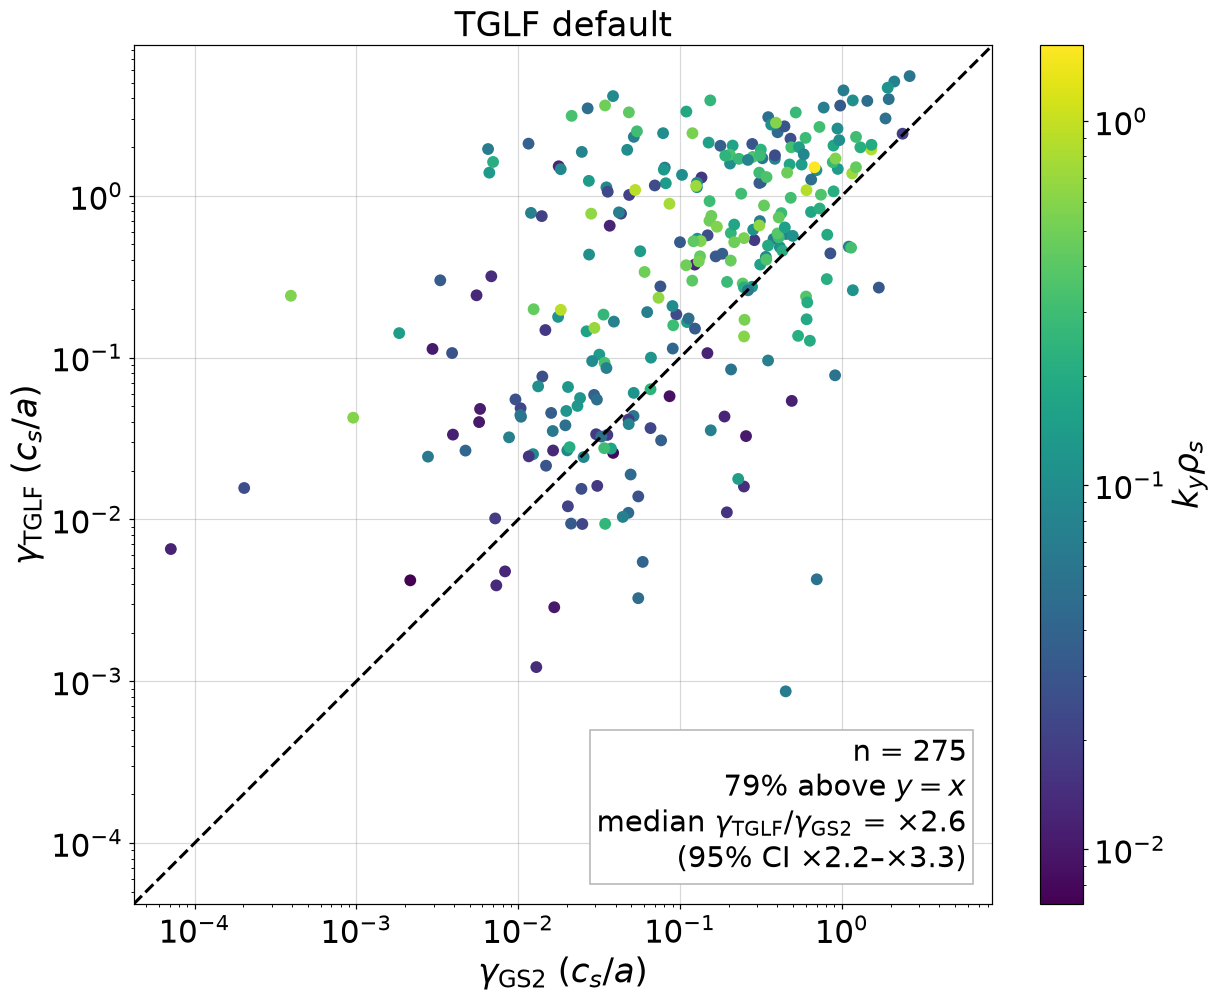

In [4]:
fig, ax = plt.subplots(figsize=(11, 9))
points = ax.scatter(gamma_gs2[found], gamma_tglf[found], c=ky_gs2[found], cmap="viridis", norm=LogNorm(), s=60, edgecolors="none")
ax.set(xscale="log", yscale="log", xlabel=r"$\gamma_{\rm GS2}$ ($c_s/a$)", ylabel=r"$\gamma_{\rm TGLF}$ ($c_s/a$)", title="TGLF default")
low = min(ax.get_xlim()[0], ax.get_ylim()[0])
high = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([low, high], [low, high], "k--", lw=2)
ax.set(xlim=(low, high), ylim=(low, high), aspect="equal")
fig.colorbar(points, ax=ax, label=r"$k_y\rho_s$")
ax.text(0.97, 0.03, f"n = {n_found}\n{100 * fraction_above:.0f}% above $y = x$\n"
        rf"median $\gamma_{{\rm TGLF}}/\gamma_{{\rm GS2}}$ = $\times${median_ratio:.1f}" + "\n"
        rf"(95% CI $\times${ci_low:.1f}–$\times${ci_high:.1f})",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=19, bbox=dict(fc="white", ec="0.7"))
fig.savefig(plots_dir / "fig_slide09_tglf_search_bias.png", bbox_inches="tight")
plt.show()